<a href="https://colab.research.google.com/github/YaomaHG/SharkFileDataProject/blob/main/BigDataProject_OmarHG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO DE BIG DATA: ANÁLISIS EXPLORATORIO Y PATRONES DE INCIDENTES POR INTERACCIÓN CON TIBURONES**

**Omar Yahir Hernández González**

Librerías básicas

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Configuración para los gráficos
sns.set_theme(style="darkgrid")
print("Librerías cargadas de manera exitosa.")

Librerías cargadas de manera exitosa.


Carga del dataset y primeros pasos

In [ ]:
df = pd.read_csv('GSAF5.xls.csv', encoding='latin1', low_memory=False)

print("Filas y columnas iniciales:", df.shape)
df.head()

Filas y columnas iniciales: (6462, 257)


,index,Case Number,Date,Year,Type,Country,Area,Location,Activity,Name,...,Unnamed: 246,Unnamed: 247,Unnamed: 248,Unnamed: 249,Unnamed: 250,Unnamed: 251,Unnamed: 252,Unnamed: 253,Unnamed: 254,Unnamed: 255
0,0,2020.02.05,05-Feb-2020,2020.0,Unprovoked,USA,Maui,NaN,Stand-Up Paddle boarding,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2020.01.30.R,Reported 30-Jan-2020,2020.0,Provoked,BAHAMAS,Exumas,NaN,Floating,Ana Bruna Avila,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2020.01.17,17-Jan-2020,2020.0,Unprovoked,AUSTRALIA,New South Wales,Windang Beach,Surfing,Will Schroeter,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2020.01.16,16-Jan-2020,2020.0,Unprovoked,NEW ZEALAND,Southland,Oreti Beach,Surfing,Jordan King,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2020.01.13,13-Jan-2020,2020.0,Unprovoked,USA,North Carolina,"Rodanthe, Dare County",Surfing,Samuel Horne,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Limpieza de columnas y filas vacías

In [ ]:
#1. Quitar espacios en blanco de los nombres de las columnas
df.columns = df.columns.str.strip()

#2. Eliminar automáticamente todas las columnas vacías sobrantes que en la tabla empiezan con "Unnamed"
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]

#3. Eliminar columnas repetidas o que no se van a usar
columnas_borrar = ['Case Number.1', 'Case Number.2', 'href formula', 'pdf', 'original order']
df = df.drop(columns=columnas_borrar, errors='ignore')

#4. Dejar solo las filas que sí tienen un caso registrado
df = df.dropna(subset=['Case Number'])

print("Filas y columnas después de limpiar:", df.shape)
print("\nColumnas limpias que quedaron:")
print(list(df.columns))

Filas y columnas después de limpiar: (6460, 17)

Columnas limpias que quedaron:
['index', 'Case Number', 'Date', 'Year', 'Type', 'Country', 'Area', 'Location', 'Activity', 'Name', 'Age', 'Injury', 'Fatal (Y/N)', 'Time', 'Species', 'Investigator or Source', 'href']


Limpieza de la columna Fatal (Y/N)

In [ ]:
#Se pasa todo a texto, mayúsculas y se quitan espacios
df['Fatal (Y/N)'] = df['Fatal (Y/N)'].astype(str).str.strip().str.upper()

#Función
def clasificar_fatalidad(valor):
    if valor == 'Y':
        return 'Fatal'
    elif valor == 'N':
        return 'No Fatal'
    else:
        return 'Desconocido'

#Se crea una columna nueva y limpia
df['Fatalidad'] = df['Fatal (Y/N)'].apply(clasificar_fatalidad)

#Ver cuántos casos hay de cada uno
print(df['Fatalidad'].value_counts())

Fatalidad
No Fatal       4438
Fatal          1401
Desconocido     621
Name: count, dtype: int64


Filtrar por año y limpiar edad

In [ ]:
#Se convierte año a número, si hay texto o errores los convierte en vacío.
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

#Se filtra estrictamente entre 1900 y la era actual
df_moderno = df[(df['Year'] >= 1900) & (df['Year'] <= 2026)].copy()

#Se convierte edad a número
df_moderno['Age'] = pd.to_numeric(df_moderno['Age'], errors='coerce')

print(f"Rango de años analizados: desde {int(df_moderno['Year'].min())} hasta {int(df_moderno['Year'].max())}")
print("Total de casos filtrados:", len(df_moderno))

Rango de años analizados: desde 1900 hasta 2020
Total de casos filtrados: 5717


Agrupar actividades comunes

In [ ]:
#Función que agrupa las actividades más repetidas
def agrupar_actividad(texto):
    texto = str(texto).lower()

    if 'surf' in texto or 'board' in texto:
        return 'Surf / Deportes de tabla'
    elif 'swim' in texto or 'bath' in texto or 'wading' in texto:
        return 'Nado / Baño'
    elif 'dive' in texto or 'diving' in texto or 'snorkel' in texto:
        return 'Buceo / Snorkel'
    elif 'fish' in texto:
        return 'Pesca'
    else:
        return 'Otras actividades'

df_moderno['Actividad_Grupo'] = df_moderno['Activity'].apply(agrupar_actividad)

print(df_moderno['Actividad_Grupo'].value_counts())

Actividad_Grupo
Surf / Deportes de tabla    1567
Otras actividades           1272
Nado / Baño                 1213
Pesca                       1044
Buceo / Snorkel              621
Name: count, dtype: int64


Visualizaciones clave (EDA)

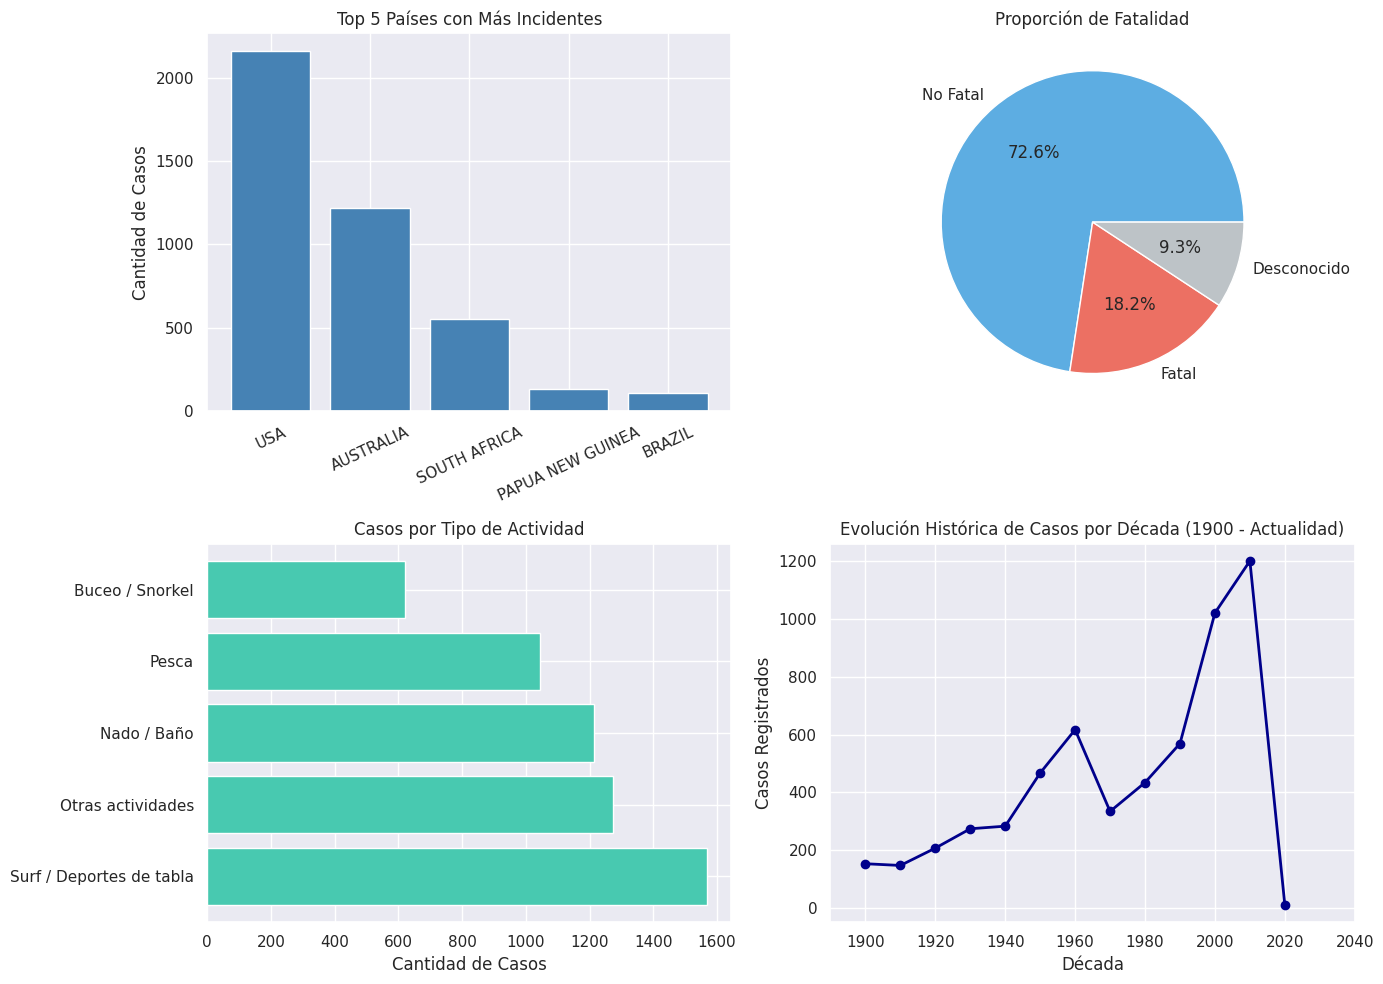

In [ ]:
#Lienzo para gráficas (2 arriba y 2 abajo)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#1. Top 5 países con más ataques
top_paises = df_moderno['Country'].str.strip().str.upper().value_counts().head(5)
axes[0, 0].bar(top_paises.index, top_paises.values, color='steelblue')
axes[0, 0].set_title('Top 5 Países con Más Incidentes')
axes[0, 0].set_ylabel('Cantidad de Casos')
axes[0, 0].tick_params(axis='x', rotation=25)

#2. Porcentaje de Fatalidad
conteo_fatal = df_moderno['Fatalidad'].value_counts()
axes[0, 1].pie(conteo_fatal, labels=conteo_fatal.index, autopct='%1.1f%%', colors=['#5dade2', '#ec7063', '#bdc3c7'])
axes[0, 1].set_title('Proporción de Fatalidad')

#3. Incidentes por Actividad
actividades = df_moderno['Actividad_Grupo'].value_counts()
axes[1, 0].barh(actividades.index, actividades.values, color='#48c9b0')
axes[1, 0].set_title('Casos por Tipo de Actividad')
axes[1, 0].set_xlabel('Cantidad de Casos')

#4. Tendencia por Décadas (Evolución en el tiempo)
df_moderno['Decada'] = (df_moderno['Year'] // 10) * 10
casos_decada = df_moderno['Decada'].value_counts().sort_index()
axes[1, 1].plot(casos_decada.index, casos_decada.values, marker='o', color='darkblue', linewidth=2)
axes[1, 1].set_title('Evolución Histórica de Casos por Década (1900 - Actualidad)')
axes[1, 1].set_xlabel('Década')
axes[1, 1].set_ylabel('Casos Registrados')
axes[1, 1].set_xlim(1890, 2040)

plt.tight_layout()
plt.show()

Exportación de dataset limpio

In [ ]:
df_moderno.to_csv('GSAF_limpio.csv', index=False)
print("Archivo 'GSAF_limpio.csv' guardado con éxito.")

Archivo 'GSAF_limpio.csv' guardado con éxito.
